In [124]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker



In [125]:
df= pd.read_excel('/Users/rokiialaa/Desktop/ML/telecomchurn/notebook/data/Telco_customer_churn.xlsx')


In [126]:
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [127]:
df.duplicated().sum()

np.int64(0)

In [128]:
df.isna().sum() 

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

In [129]:
df['Churn Label'].value_counts()

#churn reason is null because its only applicable when churn is yes

Churn Label
No     5174
Yes    1869
Name: count, dtype: int64

In [130]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

Features :
CustomerID and Count 

Categorical --> Country, State, City, Gender, Partner, Dependents, Phone Service, Multiple Lines, Internet Service, Online Security, Online Backup, Device Protection, Tech Support, Streaming TV, Streaming Movies, Contract, Paperless Billing, Payment Method, Churn Label, Churn Reason

Numerical --> Tenure Months, Monthly Charges, Total Charges, Churn Value, Churn Score, CLTV

Geographical --> Lat Long, Latitude, Longitude, Zip Code (will keep only latitude and longitude )


In [131]:
df['Count'].value_counts()

Count
1    7043
Name: count, dtype: int64

In [132]:
df= df.drop(columns=['CustomerID','Count'])

/var/folders/nd/rgq9d99j35x4ykbz3pyy4c2r0000gn/T/ipykernel_27383/3913999084.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Churn Label', data=df, palette='BuPu')


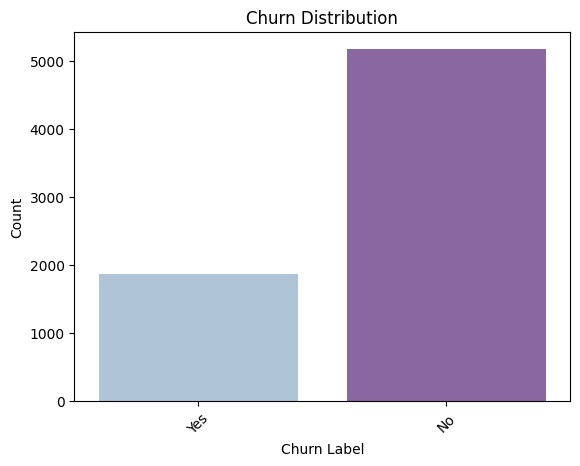

In [133]:
#check data balance
sns.countplot(x='Churn Label', data=df, palette='BuPu')
plt.title('Churn Distribution')
plt.xlabel('Churn Label')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()



In [134]:
print(df['Country'].value_counts()) #drop
print(df['State'].value_counts())#drop
print(df['City'].value_counts())#keep

Country
United States    7043
Name: count, dtype: int64
State
California    7043
Name: count, dtype: int64
City
Los Angeles       305
San Diego         150
San Jose          112
Sacramento        108
San Francisco     104
                 ... 
Healdsburg          4
Jenner              4
Philo               4
Point Arena         4
Olympic Valley      4
Name: count, Length: 1129, dtype: int64


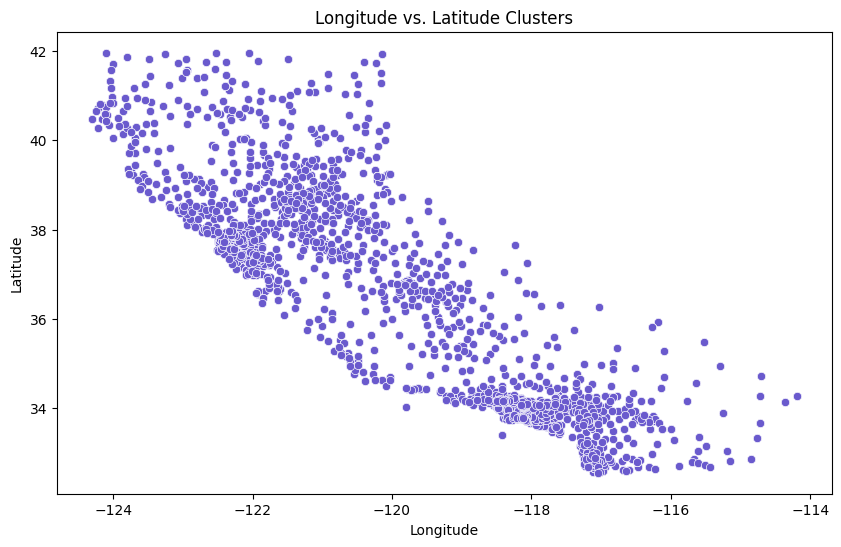

In [135]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Longitude', y='Latitude', data=df, color='#6A5ACD')
plt.title('Longitude vs. Latitude Clusters')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

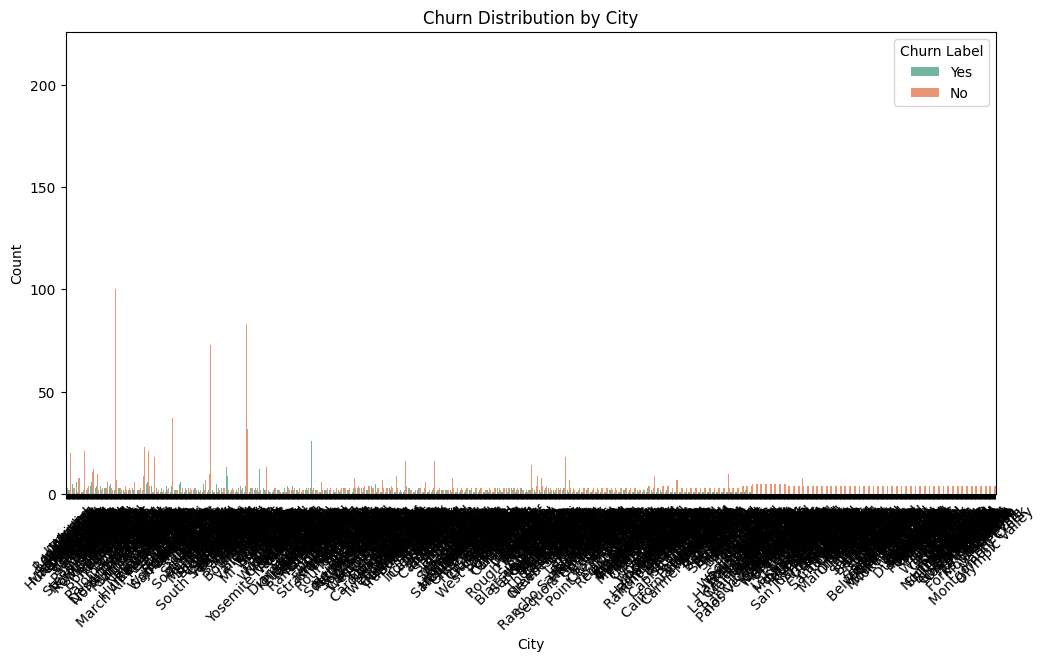

In [136]:
#city vs churn
plt.figure(figsize=(12, 6))
sns.countplot(x='City', hue='Churn Label', data=df, palette='Set2')
plt.title('Churn Distribution by City')         
plt.xlabel('City')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.legend(title='Churn Label')
plt.show()


In [137]:
df=df.drop(columns=['Country','State'])

In [138]:
df= df.drop(columns=['Zip Code', 'Lat Long'])

In [139]:
df.tail()

,City,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
7038,Landers,34.341737,-116.539416,Female,No,No,No,72,Yes,No,...,Two year,Yes,Bank transfer (automatic),21.15,1419.4,No,0,45,5306,NaN
7039,Adelanto,34.667815,-117.536183,Male,No,Yes,Yes,24,Yes,Yes,...,One year,Yes,Mailed check,84.80,1990.5,No,0,59,2140,NaN
7040,Amboy,34.559882,-115.637164,Female,No,Yes,Yes,72,Yes,Yes,...,One year,Yes,Credit card (automatic),103.20,7362.9,No,0,71,5560,NaN
7041,Angelus Oaks,34.167800,-116.864330,Female,No,Yes,Yes,11,No,No phone service,...,Month-to-month,Yes,Electronic check,29.60,346.45,No,0,59,2793,NaN
7042,Apple Valley,34.424926,-117.184503,Male,No,No,No,66,Yes,No,...,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No,0,38,5097,NaN


In [140]:
print(df.columns.tolist())

['City', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason']


Categorical Analysis
1) demographics[Gender,Senior Citizen, Partner, Dependents]
2) services[Phone Service, Multiple Lines, Internet Services,Online Security, Online Backup, Device Protection, Tech Support, Streaming TV, Streaming Movies]
3) bill payment and contract


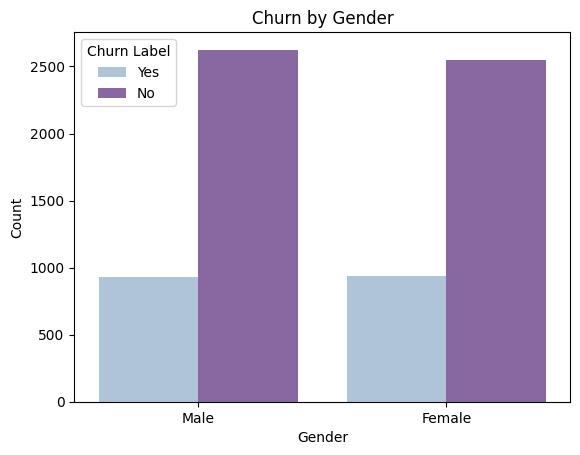

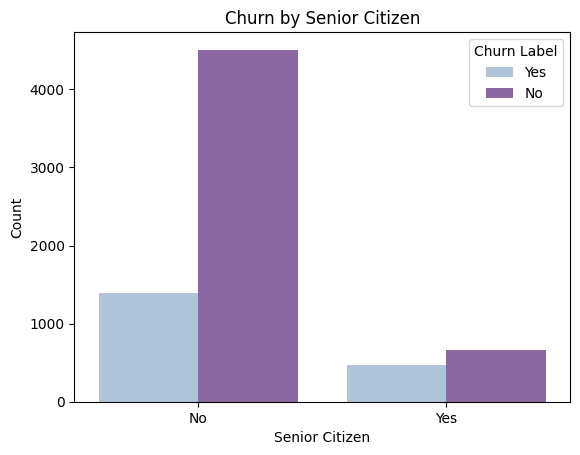

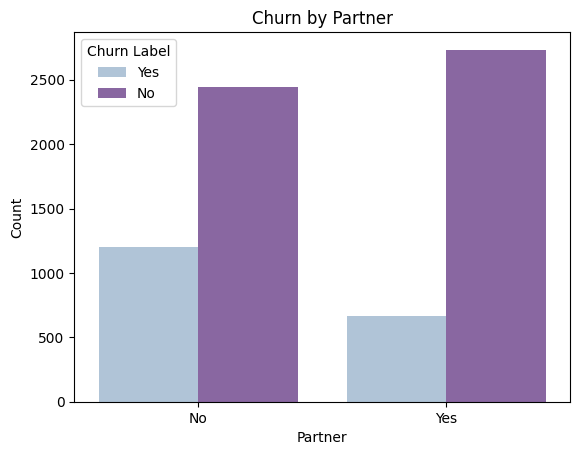

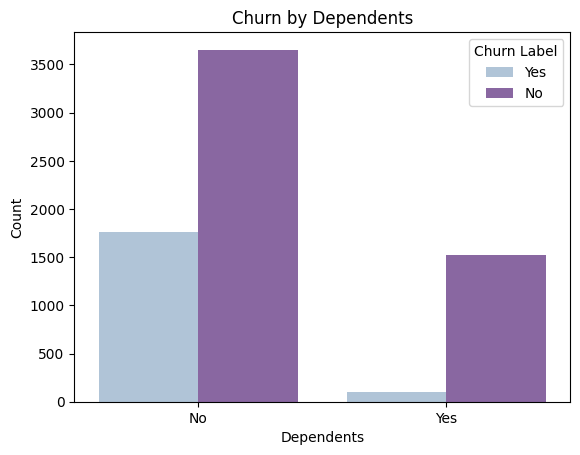

In [141]:

demographics = ['Gender', 'Senior Citizen', 'Partner', 'Dependents']
for feature in demographics:
    sns.countplot(x=feature, hue='Churn Label', data=df, palette='BuPu')
    plt.title(f'Churn by {feature}')
    plt.xlabel(feature)
    plt.ylabel('Count')
    plt.legend(title='Churn Label')
    plt.show()


In [142]:
#churn rate by label and  total of label and churn rate by label
#for each feature in demographics, calculate churn rate and print it

for feature in demographics:    
    churn_rate = df.groupby(feature)['Churn Label'].value_counts(normalize=True).unstack()
    churn_rate = churn_rate.rename(columns={'No': 'Not Churned', 'Yes': 'Churned'})
    churn_rate['Churn Rate'] = churn_rate['Churned'] * 100 

    print(f"\nChurn Rate by {feature}:\n")
    print(churn_rate[['Churned', 'Not Churned', 'Churn Rate']])    


# gender is not an indicator
# senior citizen is an indicator
# partner is an indicator
# dependents is the strongest indicator 





Churn Rate by Gender:

Churn Label   Churned  Not Churned  Churn Rate
Gender                                        
Female       0.269209     0.730791   26.920872
Male         0.261603     0.738397   26.160338

Churn Rate by Senior Citizen:

Churn Label      Churned  Not Churned  Churn Rate
Senior Citizen                                   
No              0.236062     0.763938   23.606168
Yes             0.416813     0.583187   41.681261

Churn Rate by Partner:

Churn Label   Churned  Not Churned  Churn Rate
Partner                                       
No           0.329580     0.670420   32.957979
Yes          0.196649     0.803351   19.664903

Churn Rate by Dependents:

Churn Label   Churned  Not Churned  Churn Rate
Dependents                                    
No           0.325517     0.674483   32.551699
Yes          0.065151     0.934849    6.515058


In [143]:
services= ['Phone Service', 'Multiple Lines', 'Internet Service',
 'Online Security', 'Online Backup', 'Device Protection',
 'Tech Support', 'Streaming TV', 'Streaming Movies']


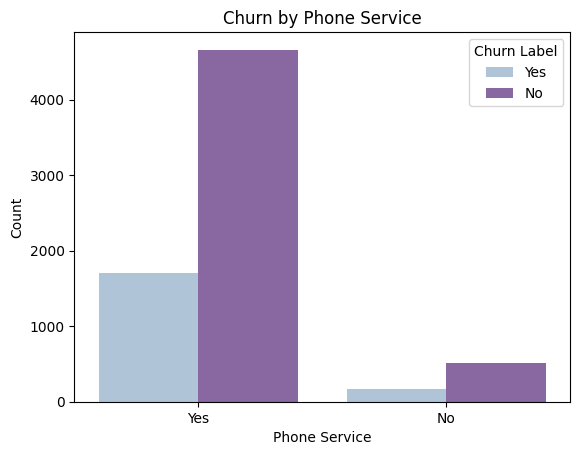

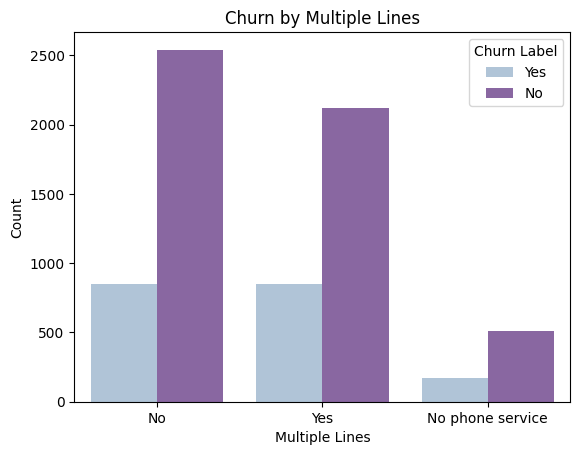

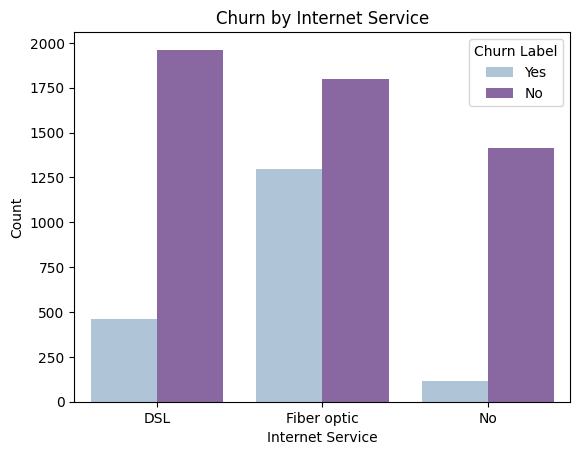

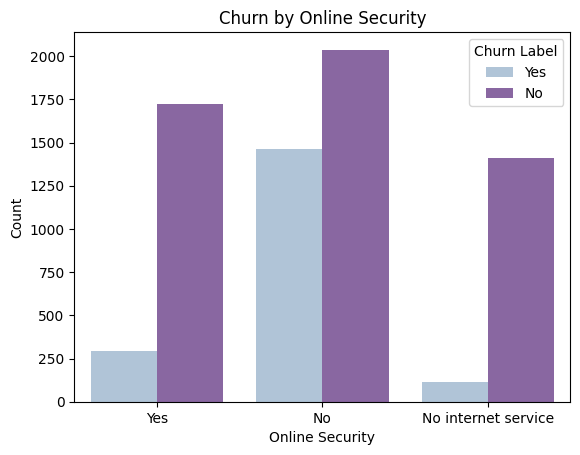

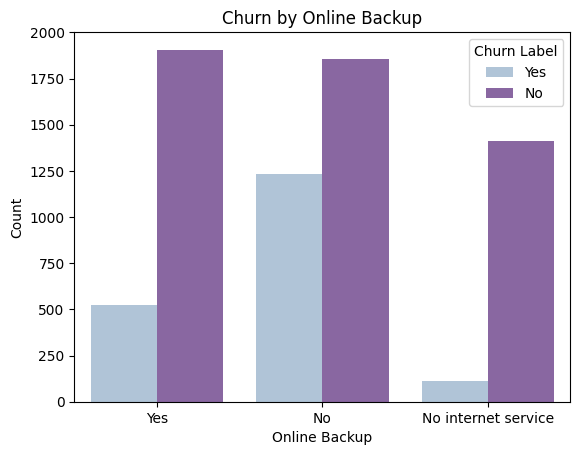

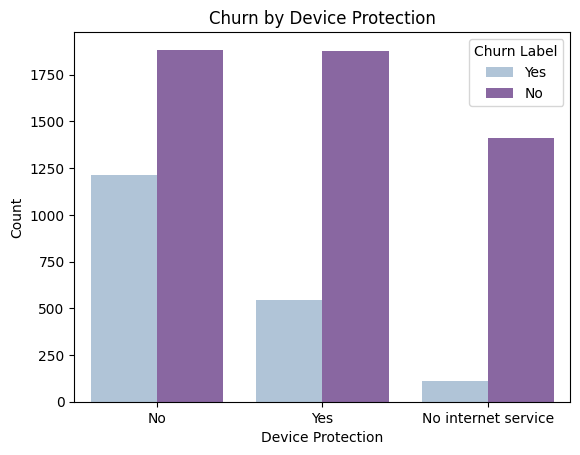

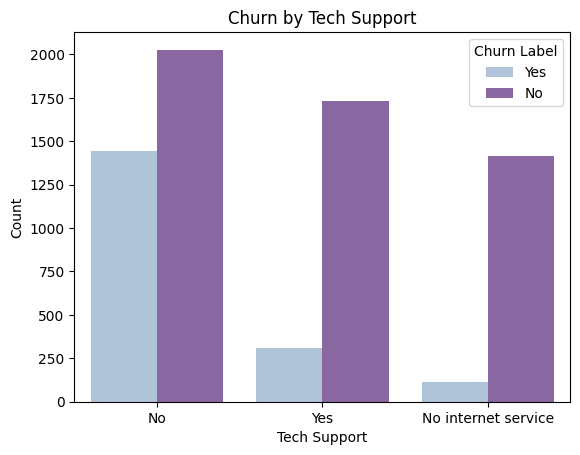

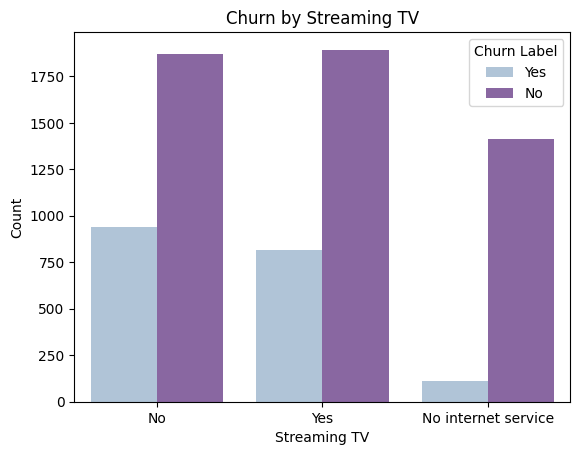

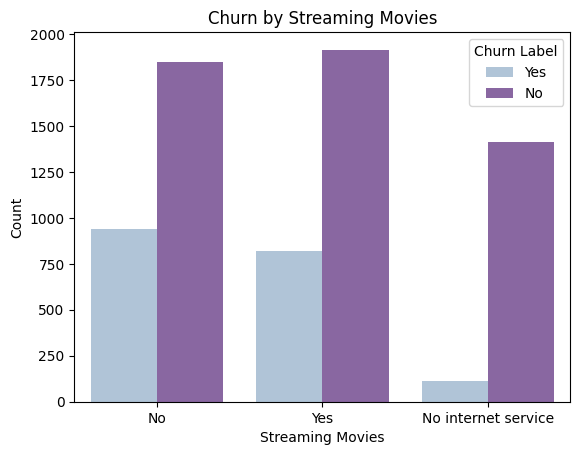

In [144]:
for feature in services:
    sns.countplot(x=feature, hue='Churn Label', data=df, palette='BuPu')
    plt.title(f'Churn by {feature}')
    plt.xlabel(feature)
    plt.ylabel('Count')
    plt.legend(title='Churn Label')
    plt.show()


In [145]:
for feature in services:    
    churn_rate = df.groupby(feature)['Churn Label'].value_counts(normalize=True).unstack()
    churn_rate = churn_rate.rename(columns={'No': 'Not Churned', 'Yes': 'Churned'})
    churn_rate['Churn Rate'] = churn_rate['Churned'] * 100 

    print(f"\nChurn Rate by {feature}:\n")
    print(churn_rate[['Churned', 'Not Churned', 'Churn Rate']])    



Churn Rate by Phone Service:

Churn Label     Churned  Not Churned  Churn Rate
Phone Service                                   
No             0.249267     0.750733   24.926686
Yes            0.267096     0.732904   26.709637

Churn Rate by Multiple Lines:

Churn Label        Churned  Not Churned  Churn Rate
Multiple Lines                                     
No                0.250442     0.749558   25.044248
No phone service  0.249267     0.750733   24.926686
Yes               0.286099     0.713901   28.609896

Churn Rate by Internet Service:

Churn Label        Churned  Not Churned  Churn Rate
Internet Service                                   
DSL               0.189591     0.810409   18.959108
Fiber optic       0.418928     0.581072   41.892765
No                0.074050     0.925950    7.404980

Churn Rate by Online Security:

Churn Label           Churned  Not Churned  Churn Rate
Online Security                                       
No                   0.417667     0.582333  

In [146]:
def merge_streaming(row):
    if row['Streaming TV'] == 'Yes' or row['Streaming Movies'] == 'Yes':
        return 'Yes'
    else:
        return 'No'

df['Streaming'] = df.apply(merge_streaming, axis=1)
df = df.drop(columns=['Streaming TV', 'Streaming Movies'])


Churn Rate by Service Count:

Churn Label     Churned  Not Churned  Churn Rate
Service Count                                   
0              0.219588     0.780412   21.958803
1              0.394265     0.605735   39.426523
2              0.270444     0.729556   27.044393
3              0.166974     0.833026   16.697417


/var/folders/nd/rgq9d99j35x4ykbz3pyy4c2r0000gn/T/ipykernel_27383/908452010.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=churn_rate_service_count.index, y='Churn Rate', data=churn_rate_service_count.reset_index(), palette='BuPu')


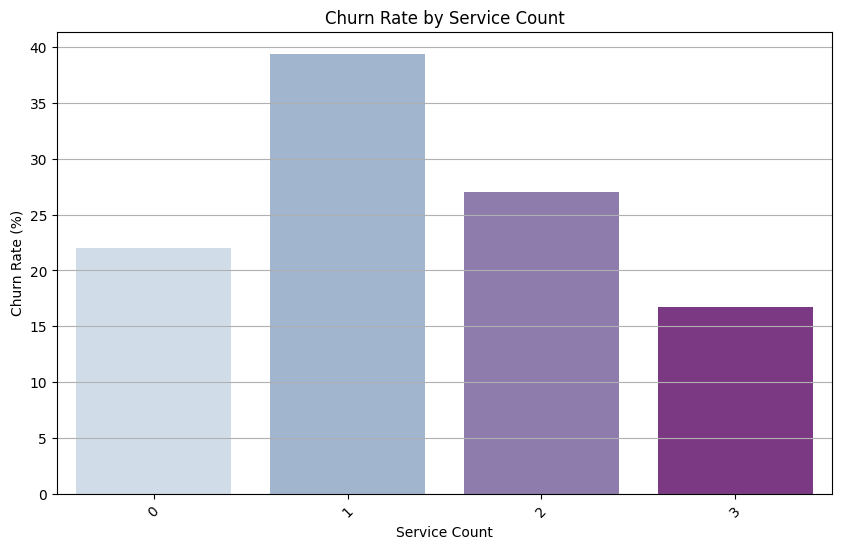

In [147]:
df = df.drop(columns=['Phone Service', 'Multiple Lines'])

agg_services = ['Online Backup', 'Device Protection','Streaming']

def service_count(row):
    count = 0
    for service in agg_services:
        if row[service] == 'Yes':
            count += 1
    return count

df_services = df.copy()


df_services['Service Count'] = df.apply(service_count, axis=1)

churn_rate_service_count = df_services.groupby('Service Count')['Churn Label'].value_counts(normalize=True).unstack()
churn_rate_service_count = churn_rate_service_count.rename(columns={'No': 'Not Churned', 'Yes': 'Churned'})
churn_rate_service_count['Churn Rate'] = churn_rate_service_count['Churned'] * 100  
print("\nChurn Rate by Service Count:\n")
print(churn_rate_service_count[['Churned', 'Not Churned', 'Churn Rate']])

plt.figure(figsize=(10, 6)) 
sns.barplot(x=churn_rate_service_count.index, y='Churn Rate', data=churn_rate_service_count.reset_index(), palette='BuPu')
plt.title('Churn Rate by Service Count')
plt.xlabel('Service Count')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()



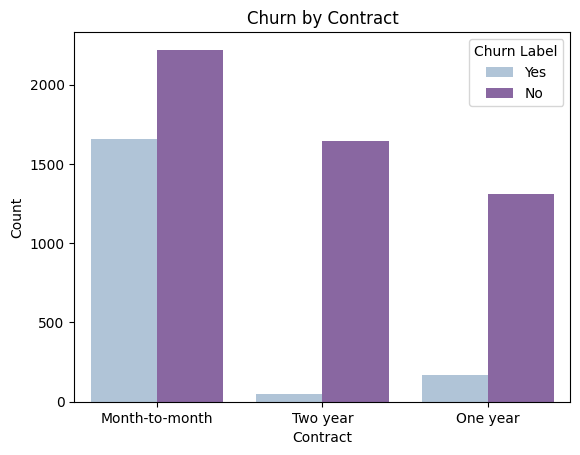

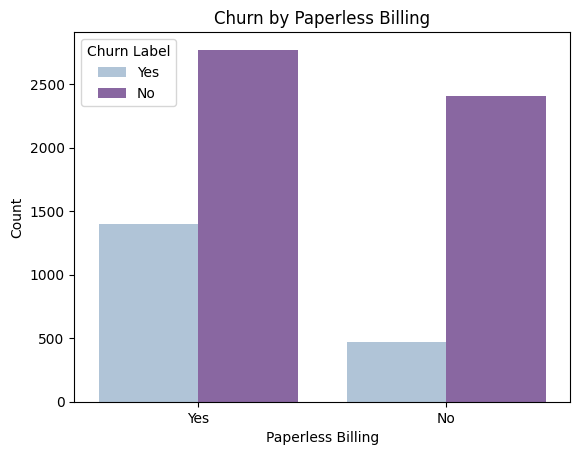

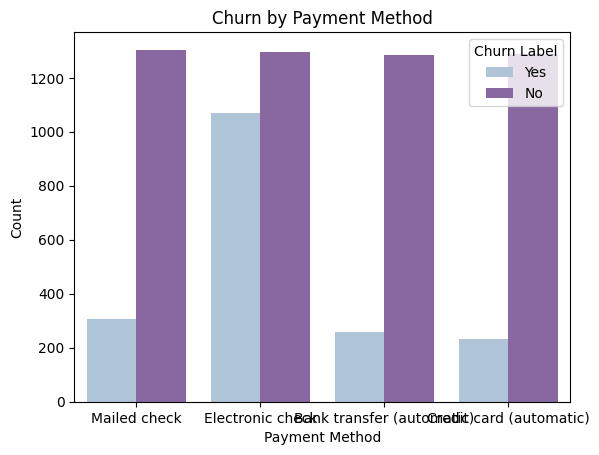

In [148]:

bill_contract = ['Contract', 'Paperless Billing', 'Payment Method']
for feature in bill_contract:
    sns.countplot(x=feature, hue='Churn Label', data=df, palette='BuPu')
    plt.title(f'Churn by {feature}')
    plt.xlabel(feature)
    plt.ylabel('Count')
    plt.legend(title='Churn Label')
    plt.show()

#pie chart for bill_contract type


In [149]:
for feature in bill_contract:
    churn_rate = df.groupby(feature)['Churn Label'].value_counts(normalize=True).unstack()
    churn_rate = churn_rate.rename(columns={'No': 'Not Churned', 'Yes': 'Churned'})
    churn_rate['Churn Rate'] = churn_rate['Churned'] * 100 

    print(f"\nChurn Rate by {feature}:\n")
    print(churn_rate[['Churned', 'Not Churned', 'Churn Rate']])




Churn Rate by Contract:

Churn Label      Churned  Not Churned  Churn Rate
Contract                                         
Month-to-month  0.427097     0.572903   42.709677
One year        0.112695     0.887305   11.269518
Two year        0.028319     0.971681    2.831858

Churn Rate by Paperless Billing:

Churn Label         Churned  Not Churned  Churn Rate
Paperless Billing                                   
No                 0.163301     0.836699   16.330084
Yes                0.335651     0.664349   33.565092

Churn Rate by Payment Method:

Churn Label                 Churned  Not Churned  Churn Rate
Payment Method                                              
Bank transfer (automatic)  0.167098     0.832902   16.709845
Credit card (automatic)    0.152431     0.847569   15.243101
Electronic check           0.452854     0.547146   45.285412
Mailed check               0.191067     0.808933   19.106700


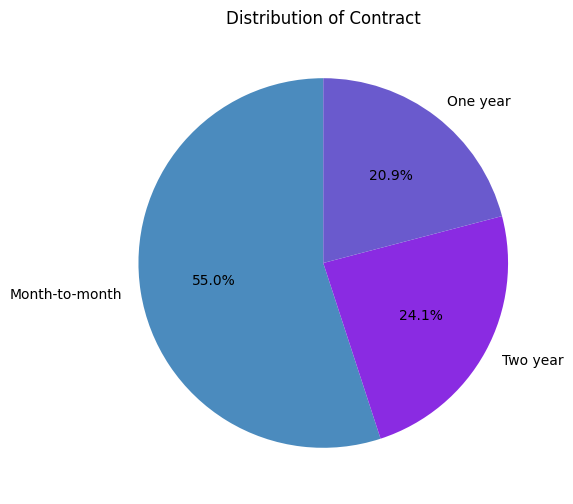

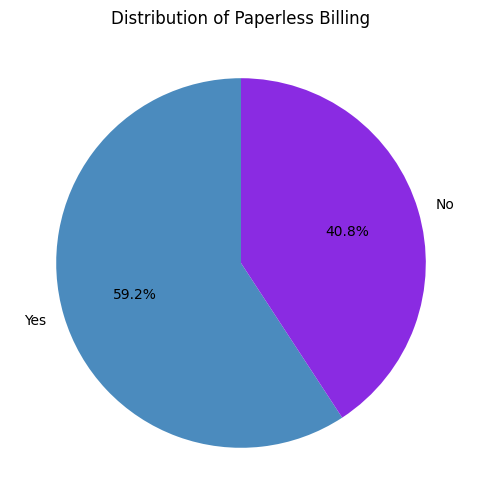

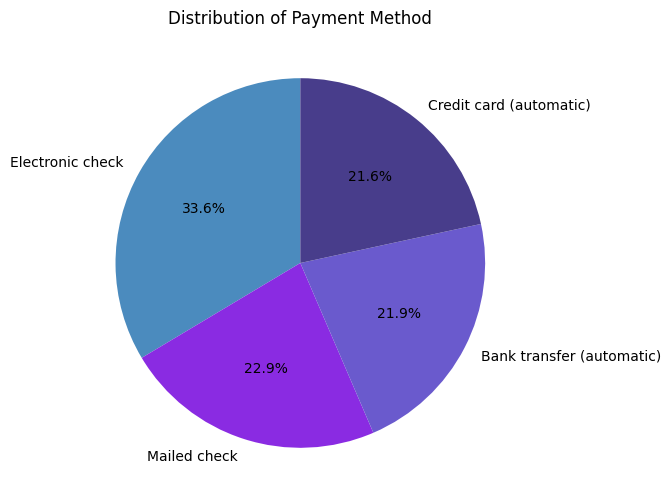

In [150]:
custom_palette = ['#4B8BBE', '#8A2BE2', '#6A5ACD', '#483D8B', '#4169E1', '#9370DB']

for feature in bill_contract:
    plt.figure(figsize=(6, 6))
    df[feature].value_counts().plot.pie(autopct='%1.1f%%', startangle=90, colors=custom_palette)
    plt.title(f'Distribution of {feature}')
    plt.ylabel('')
    plt.show()

Numerical Analysis 
1) Tenure Months
2) Monthly Charge
3) Total Charge 


Text Analysis
1) Churn Reason

In [151]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   City               7043 non-null   object 
 1   Latitude           7043 non-null   float64
 2   Longitude          7043 non-null   float64
 3   Gender             7043 non-null   object 
 4   Senior Citizen     7043 non-null   object 
 5   Partner            7043 non-null   object 
 6   Dependents         7043 non-null   object 
 7   Tenure Months      7043 non-null   int64  
 8   Internet Service   7043 non-null   object 
 9   Online Security    7043 non-null   object 
 10  Online Backup      7043 non-null   object 
 11  Device Protection  7043 non-null   object 
 12  Tech Support       7043 non-null   object 
 13  Contract           7043 non-null   object 
 14  Paperless Billing  7043 non-null   object 
 15  Payment Method     7043 non-null   object 
 16  Monthly Charges    7043 

In [152]:
print(type(df['Total Charges'].iloc[0])) 
df['Total Charges'] = df['Total Charges'].replace(r'^\s*$', np.nan, regex=True)



<class 'float'>


/var/folders/nd/rgq9d99j35x4ykbz3pyy4c2r0000gn/T/ipykernel_27383/217889792.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Total Charges'] = df['Total Charges'].replace(r'^\s*$', np.nan, regex=True)


In [153]:
print(df['Total Charges'].isna().sum())


11


In [154]:
total_charges_rows = df[df['Total Charges'].isna()]
print(total_charges_rows[['Tenure Months', 'Monthly Charges', 'Total Charges', 'Churn Label']])


      Tenure Months  Monthly Charges  Total Charges Churn Label
2234              0            52.55            NaN          No
2438              0            20.25            NaN          No
2568              0            80.85            NaN          No
2667              0            25.75            NaN          No
2856              0            56.05            NaN          No
4331              0            19.85            NaN          No
4687              0            25.35            NaN          No
5104              0            20.00            NaN          No
5719              0            19.70            NaN          No
6772              0            73.35            NaN          No
6840              0            61.90            NaN          No


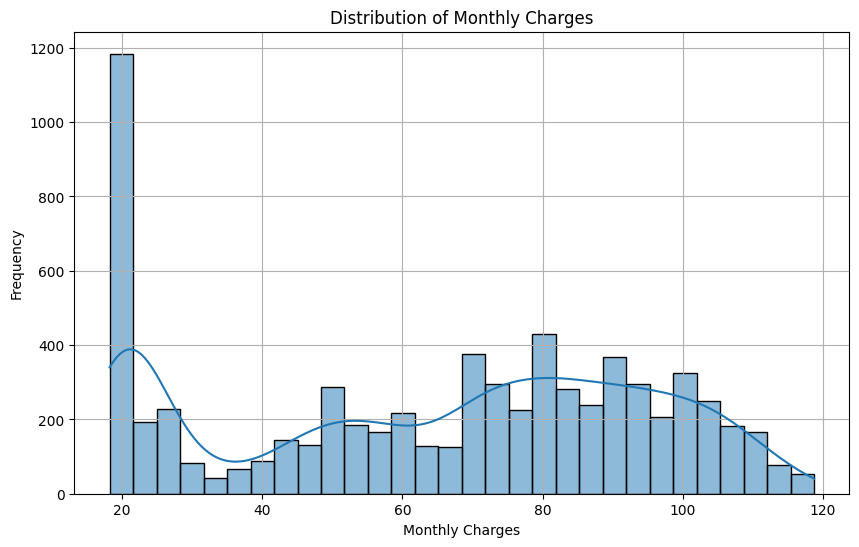

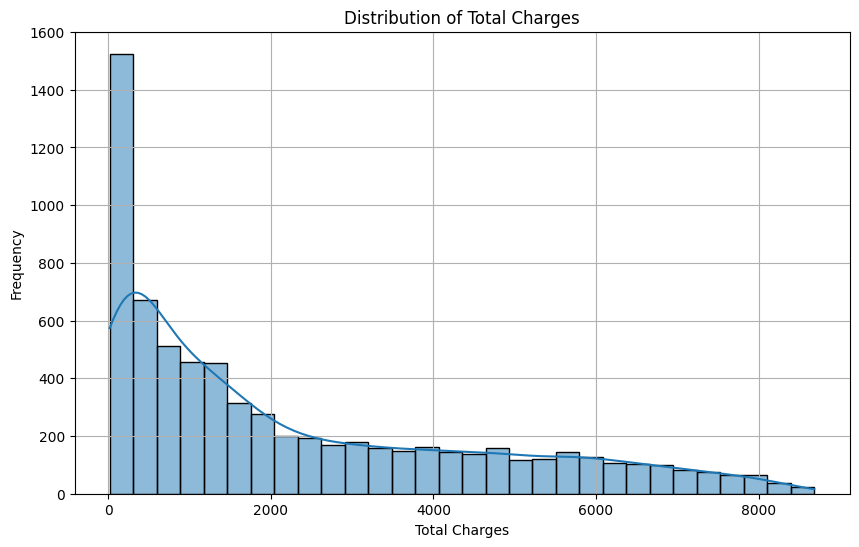

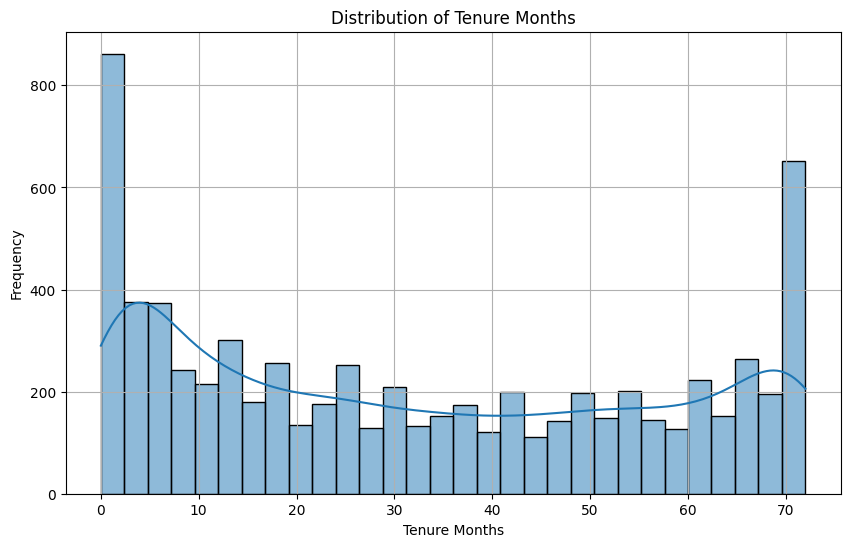

In [155]:
#distribution of numerical features
numerical_features = ['Monthly Charges', 'Total Charges', 'Tenure Months']
for feature in numerical_features:
    plt.figure(figsize=(10, 6))
    sns.histplot(df[feature], bins=30, kde=True)
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.grid(True)
    plt.show()
    

#

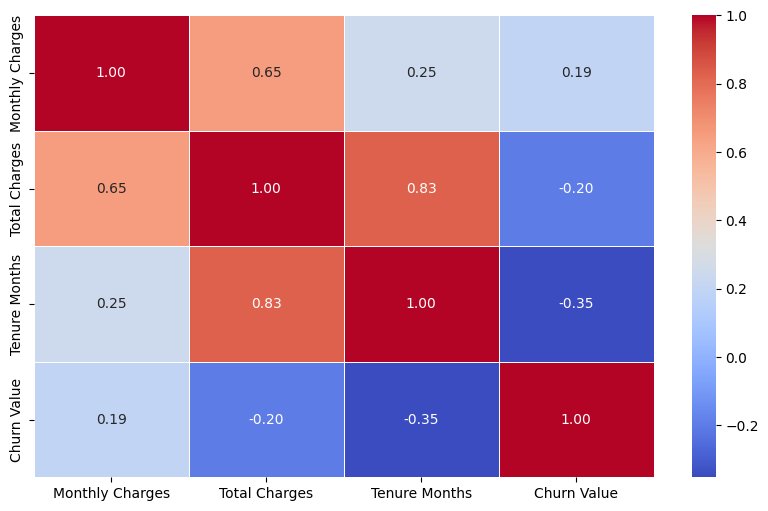

In [156]:
#correlation of numerical features with churn label
corr_features = numerical_features + ['Churn Value']
corr_df = df[corr_features]
corr_matrix = corr_df.corr()

plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.show()

#correlations of numeric with churn value 




In [157]:
#show all columns in df
print(df.columns.tolist())


['City', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason', 'Streaming']


Preprocessing 
Handle Missing Values
Categorical Encoding
Feature Scaling
Feature Engineering(Total services , regions)

In [158]:
from sklearn.model_selection import train_test_split
X = df.drop(columns=['Churn Label', 'Churn Value','Churn Reason','CLTV','Churn Score'])
y = df['Churn Value']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [159]:
X_train['Total Charges'].fillna(0, inplace=True)
X_test['Total Charges'].fillna(0, inplace=True)
#drop total charges column
X_train = X_train.drop(columns=['Total Charges'])
X_test = X_test.drop(columns=['Total Charges'])



/var/folders/nd/rgq9d99j35x4ykbz3pyy4c2r0000gn/T/ipykernel_27383/3865119260.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  X_train['Total Charges'].fillna(0, inplace=True)
/var/folders/nd/rgq9d99j35x4ykbz3pyy4c2r0000gn/T/ipykernel_27383/3865119260.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values alwa

In [160]:
#print(X_train['Total Charges'].isna().sum())
#print(X_test['Total Charges'].isna().sum())


In [161]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5634 entries, 4626 to 6017
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   City               5634 non-null   object 
 1   Latitude           5634 non-null   float64
 2   Longitude          5634 non-null   float64
 3   Gender             5634 non-null   object 
 4   Senior Citizen     5634 non-null   object 
 5   Partner            5634 non-null   object 
 6   Dependents         5634 non-null   object 
 7   Tenure Months      5634 non-null   int64  
 8   Internet Service   5634 non-null   object 
 9   Online Security    5634 non-null   object 
 10  Online Backup      5634 non-null   object 
 11  Device Protection  5634 non-null   object 
 12  Tech Support       5634 non-null   object 
 13  Contract           5634 non-null   object 
 14  Paperless Billing  5634 non-null   object 
 15  Payment Method     5634 non-null   object 
 16  Monthly Charges    5634 no

In [162]:
from sklearn.cluster import KMeans
lat_long = ['Latitude', 'Longitude']
kmeans = KMeans(n_clusters=4, random_state=42)
X_train['Region'] = kmeans.fit_predict(X_train[lat_long])
X_test['Region'] = kmeans.predict(X_test[lat_long])


Text(0.5, 0, 'Longitude')

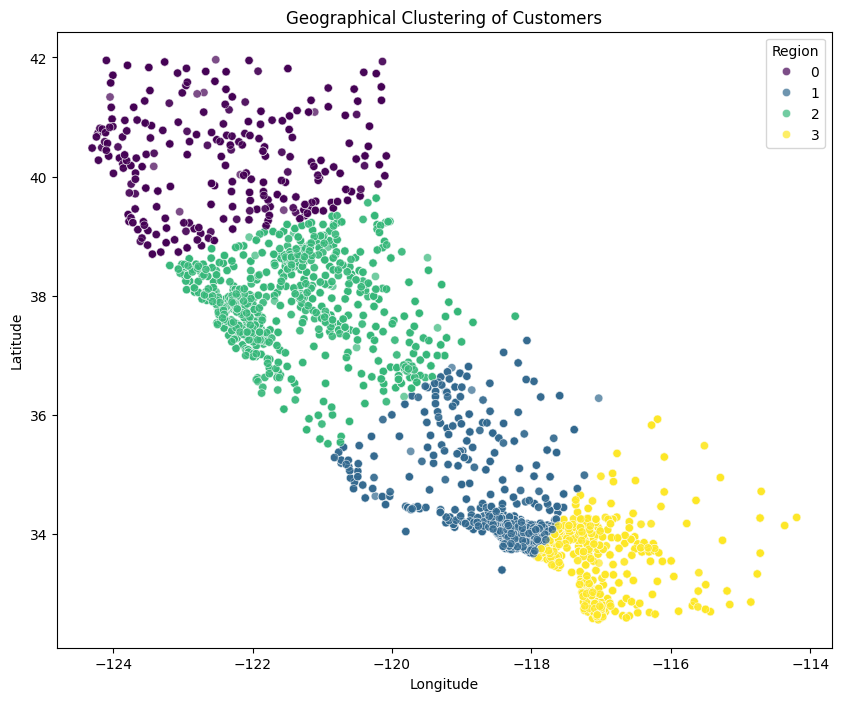

In [163]:
plt.figure(figsize=(10, 8))
sns.scatterplot(data=X_train, x='Longitude', y='Latitude', hue='Region', palette='viridis', alpha=0.7, legend='full')
plt.title('Geographical Clustering of Customers')
plt.xlabel('Longitude') 


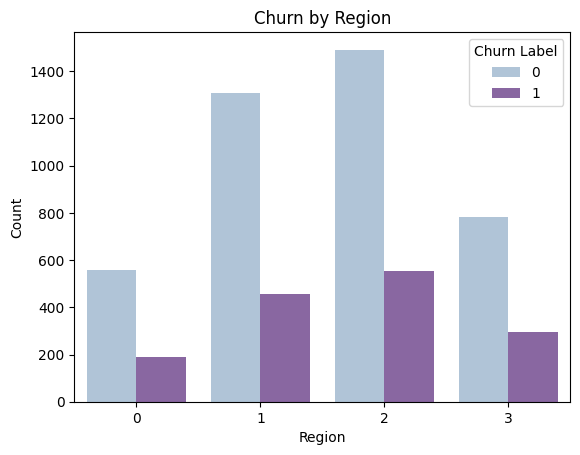


Churn Rate by Region:

Churn Label   Churned  Not Churned  Churn Rate
Region                                        
0            0.255007     0.744993   25.500668
1            0.259637     0.740363   25.963719
2            0.270191     0.729809   27.019090
3            0.272727     0.727273   27.272727


In [164]:
sns.countplot(x='Region', hue=y_train, data=X_train, palette='BuPu')
plt.title('Churn by Region')
plt.xlabel('Region')
plt.ylabel('Count')
plt.legend(title='Churn Label')
plt.show()

train_df = X_train.copy()
train_df['Churn Label'] = y_train

churn_rate_region = train_df.groupby('Region')['Churn Label'].value_counts(normalize=True).unstack()
churn_rate_region = churn_rate_region.rename(columns={0: 'Not Churned', 1: 'Churned'})
churn_rate_region['Churn Rate'] = churn_rate_region['Churned'] * 100

print("\nChurn Rate by Region:\n")
print(churn_rate_region[['Churned', 'Not Churned', 'Churn Rate']])


In [165]:
X_train= X_train.drop(columns=['Latitude', 'Longitude', 'City', 'Region'])
X_test = X_test.drop(columns=['Latitude', 'Longitude', 'City', 'Region'])


In [166]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5634 entries, 4626 to 6017
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Gender             5634 non-null   object 
 1   Senior Citizen     5634 non-null   object 
 2   Partner            5634 non-null   object 
 3   Dependents         5634 non-null   object 
 4   Tenure Months      5634 non-null   int64  
 5   Internet Service   5634 non-null   object 
 6   Online Security    5634 non-null   object 
 7   Online Backup      5634 non-null   object 
 8   Device Protection  5634 non-null   object 
 9   Tech Support       5634 non-null   object 
 10  Contract           5634 non-null   object 
 11  Paperless Billing  5634 non-null   object 
 12  Payment Method     5634 non-null   object 
 13  Monthly Charges    5634 non-null   float64
 14  Streaming          5634 non-null   object 
dtypes: float64(1), int64(1), object(13)
memory usage: 704.2+ KB


In [167]:
X_train['Service Count'] = X_train.apply(service_count, axis=1)
X_test['Service Count'] = X_test.apply(service_count, axis=1)


In [168]:
categorical_features = [
    'Gender', 'Senior Citizen', 'Partner', 'Dependents',
    'Internet Service', 'Online Security', 'Tech Support',
    'Streaming',  
    'Contract', 'Paperless Billing', 'Payment Method']


numerical_features = [
    'Tenure Months',
    'Monthly Charges',
    'Service Count'
]


In [169]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler , MinMaxScaler 

preprocessor = ColumnTransformer(
    transformers=[
        ('num', MinMaxScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

X_train_processed_array = preprocessor.fit_transform(X_train)
X_test_processed_array = preprocessor.transform(X_test)

transformed_feature_names = preprocessor.get_feature_names_out()


X_train_processed = pd.DataFrame(X_train_processed_array, columns=transformed_feature_names, index=X_train.index)
X_test_processed = pd.DataFrame(X_test_processed_array, columns=transformed_feature_names, index=X_test.index)

X_train_processed.info()


<class 'pandas.core.frame.DataFrame'>
Index: 5634 entries, 4626 to 6017
Data columns (total 31 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   num__Tenure Months                             5634 non-null   float64
 1   num__Monthly Charges                           5634 non-null   float64
 2   num__Service Count                             5634 non-null   float64
 3   cat__Gender_Female                             5634 non-null   float64
 4   cat__Gender_Male                               5634 non-null   float64
 5   cat__Senior Citizen_No                         5634 non-null   float64
 6   cat__Senior Citizen_Yes                        5634 non-null   float64
 7   cat__Partner_No                                5634 non-null   float64
 8   cat__Partner_Yes                               5634 non-null   float64
 9   cat__Dependents_No                             5634 no

In [170]:
X_test_processed.head()

,num__Tenure Months,num__Monthly Charges,num__Service Count,cat__Gender_Female,cat__Gender_Male,cat__Senior Citizen_No,cat__Senior Citizen_Yes,cat__Partner_No,cat__Partner_Yes,cat__Dependents_No,...,cat__Streaming_Yes,cat__Contract_Month-to-month,cat__Contract_One year,cat__Contract_Two year,cat__Paperless Billing_No,cat__Paperless Billing_Yes,cat__Payment Method_Bank transfer (automatic),cat__Payment Method_Credit card (automatic),cat__Payment Method_Electronic check,cat__Payment Method_Mailed check
2196,1.000000,0.953164,1.000000,0.0,1.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
3549,0.111111,0.814649,0.333333,1.0,0.0,0.0,1.0,1.0,0.0,1.0,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
3515,0.569444,0.597409,1.000000,1.0,0.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
5162,0.250000,0.595914,0.333333,0.0,1.0,1.0,0.0,0.0,1.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4642,1.000000,0.640259,1.000000,1.0,0.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0


In [171]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_processed, y_train)


/var/folders/nd/rgq9d99j35x4ykbz3pyy4c2r0000gn/T/ipykernel_27383/255067665.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_train_balanced, palette='BuPu')


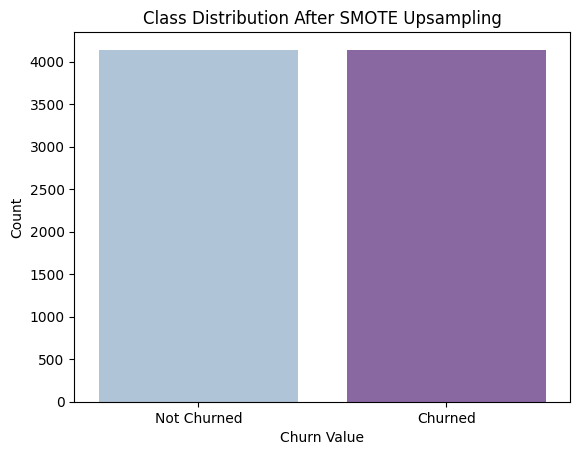

In [172]:
# Visualize class distribution after SMOTE upsampling
sns.countplot(x=y_train_balanced, palette='BuPu')
plt.title('Class Distribution After SMOTE Upsampling')
plt.xlabel('Churn Value')
plt.ylabel('Count')
plt.xticks([0, 1], ['Not Churned', 'Churned'])
plt.show()

In [173]:
from imblearn.under_sampling import AllKNN
allknn = AllKNN()
X_train_cleaned, y_train_cleaned = allknn.fit_resample(X_train_balanced, y_train_balanced)

X_train_balanced = X_train_cleaned 
y_train_balanced = y_train_cleaned

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
import lightgbm as lgb


param_grid_lr = {
    'C': np.logspace(-4, 4, 20), 
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear', 'saga'],  
    'max_iter': [1000, 2000]
}

logistic_reg = LogisticRegression(random_state=42, class_weight='balanced')
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search_lr = GridSearchCV(
    estimator=logistic_reg,
    param_grid=param_grid_lr,
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)
grid_search_lr.fit(X_train_balanced, y_train_balanced)
best_logistic_reg = grid_search_lr.best_estimator_


Fitting 5 folds for each of 160 candidates, totalling 800 fits


In [175]:
y_pred_lr = best_logistic_reg.predict(X_test_processed)
y_proba_lr = best_logistic_reg.predict_proba(X_test_processed)[:, 1]


In [176]:
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}
rf = RandomForestClassifier(random_state=42, class_weight='balanced')

grid_search_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid_rf,
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_search_rf.fit(X_train_balanced, y_train_balanced)
best_rf = grid_search_rf.best_estimator_


Fitting 5 folds for each of 216 candidates, totalling 1080 fits


In [177]:
y_pred_rf = best_rf.predict(X_test_processed)
y_proba_rf = best_rf.predict_proba(X_test_processed)[:, 1]

In [178]:
param_grid_xgb = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7, 10],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'gamma': [0, 0.1, 0.5]
}
xgb_model = xgb.XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')

grid_search_xgb = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid_xgb,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search_xgb.fit(X_train_balanced, y_train_balanced)
best_xgb = grid_search_xgb.best_estimator_


Fitting 5 folds for each of 1296 candidates, totalling 6480 fits


/Users/rokiialaa/Desktop/ML/telecomchurn/.venv/lib/python3.12/site-packages/xgboost/training.py:183: UserWarning: [10:58:11] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/Users/rokiialaa/Desktop/ML/telecomchurn/.venv/lib/python3.12/site-packages/xgboost/training.py:183: UserWarning: [10:58:11] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/Users/rokiialaa/Desktop/ML/telecomchurn/.venv/lib/python3.12/site-packages/xgboost/training.py:183: UserWarning: [10:58:11] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/Users/rokiialaa/Desktop/ML/telecomchurn/.venv/lib/python3.12/site-packages/xgboost/training.py:183: UserWarning: [10:58:11] WARNING: /Users/runn

In [179]:
y_pred_xgb = best_xgb.predict(X_test_processed)
y_proba_xgb = best_xgb.predict_proba(X_test_processed)[:, 1]

In [180]:

param_grid_lgb = {
    'n_estimators': [100, 200, 500],
    'max_depth': [10, 20, 30, -1],
    'learning_rate': [0.01, 0.05, 0.1],
    'num_leaves': [31, 50, 70],
    'reg_alpha': [0.0, 0.1, 0.5, 1.0],
    'reg_lambda': [0.0, 0.1, 0.5, 1.0]
}

In [181]:

param_grid_lgb = {
    'n_estimators': [100, 300],
    'max_depth': [10, -1],
    'learning_rate': [0.05, 0.1],
    'num_leaves': [31, 70],
    'reg_alpha': [0.0, 0.5],
    'reg_lambda': [0.0, 0.5]
}

lgb_model = lgb.LGBMClassifier(random_state=42, class_weight='balanced')

grid_search_lgb = GridSearchCV(
    estimator=lgb_model,
    param_grid=param_grid_lgb,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search_lgb.fit(X_train_balanced, y_train_balanced)
best_lgb = grid_search_lgb.best_estimator_



Fitting 5 folds for each of 64 candidates, totalling 320 fits
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 2936, number of negative: 3311
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 2936, number of negative: 3311
[LightGBM] [Info] Number of positive: 2936, number of negative: 3311
[LightGBM] [Info] Number of positive: 2936, number of negative: 3312
[LightGBM] [Info] Number of positive: 2936, number of negative: 3311
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 2936, number of negative: 3311
[LightGBM] [Warning] Found whitespace in fea

In [182]:
y_pred_lgb = best_lgb.predict(X_test_processed)
y_proba_lgb = best_lgb.predict_proba(X_test_processed)[:, 1]

In [209]:
from sklearn.metrics import classification_report
def evaluate_model(name, y_true, y_pred, y_proba):
    print(f"--- {name} ---")
    print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred):.4f}")
    print(f"Recall: {recall_score(y_true, y_pred):.4f}")
    print(f"F1 Score: {f1_score(y_true, y_pred):.4f}")
    print(f"{classification_report(y_true,y_pred)}")

evaluate_model("Logistic Regression", y_test, y_pred_lr, y_proba_lr)
evaluate_model("Random Forest", y_test, y_pred_rf, y_proba_rf)
evaluate_model("XGBoost", y_test, y_pred_xgb, y_proba_xgb)
evaluate_model("LightGBM", y_test, y_pred_lgb, y_proba_lgb)



--- Logistic Regression ---
Accuracy: 0.7410
Precision: 0.5079
Recall: 0.7781
F1 Score: 0.6146
              precision    recall  f1-score   support

           0       0.90      0.73      0.80      1035
           1       0.51      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

--- Random Forest ---
Accuracy: 0.7821
Precision: 0.6031
Recall: 0.5241
F1 Score: 0.5608
              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1035
           1       0.60      0.52      0.56       374

    accuracy                           0.78      1409
   macro avg       0.72      0.70      0.71      1409
weighted avg       0.77      0.78      0.78      1409

--- XGBoost ---
Accuracy: 0.7885
Precision: 0.6092
Recall: 0.5668
F1 Score: 0.5873
              precision    recall  f1-score   support

           0       0.85 

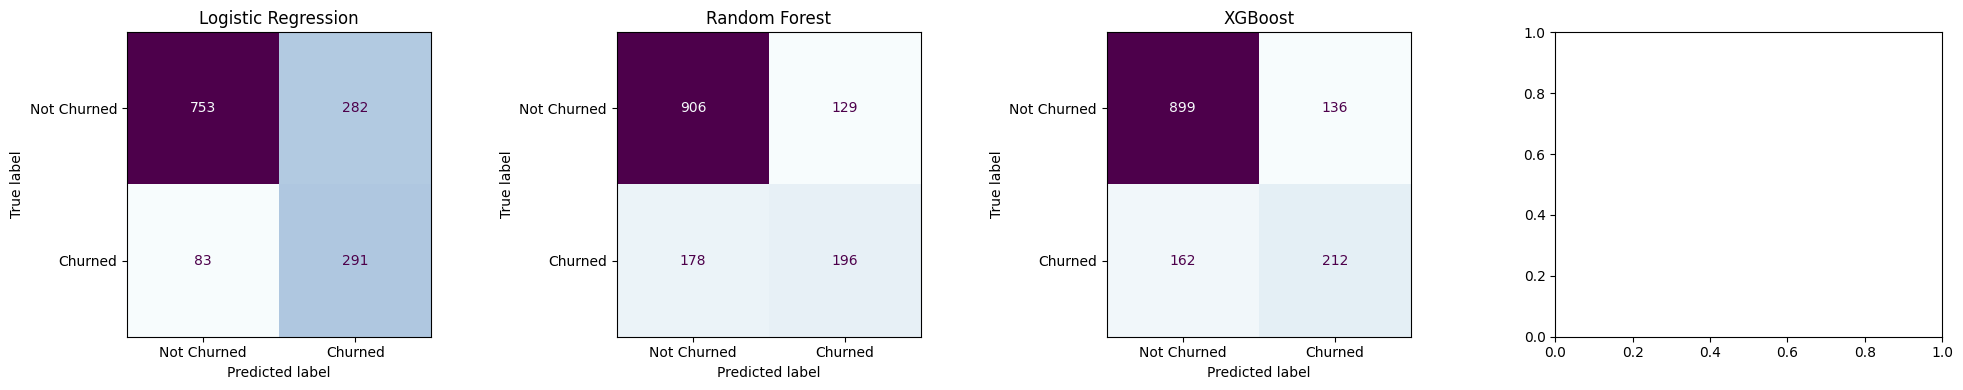

In [214]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

model_names = ["Logistic Regression", "Random Forest", "XGBoost"]
y_preds = [y_pred_lr, y_pred_rf, y_pred_xgb, y_pred_lgb]

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, name, y_pred in zip(axes, model_names, y_preds):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Churned', 'Churned'])
    disp.plot(ax=ax, cmap='BuPu', colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [ ]:

lr_risk_levels = []

for prob in y_proba_lr:
    if prob >= 0.7:
        lr_risk_levels.append('High Risk')
    elif prob >= 0.4:
        lr_risk_levels.append('Medium Risk')
    else:
        lr_risk_levels.append('Low Risk')



In [ ]:
lr_results = X_test.copy()
lr_results['Churn Probability'] = y_proba
lr_results['Churn Risk'] = lr_risk_levels
lr_results['Actual Churn'] = y_test.values


In [201]:
lr_results[['Churn Probability', 'Churn Risk', 'Actual Churn']].tail(20)


,Churn Probability,Churn Risk,Actual Churn
6728,0.085078,Low Risk,0
6460,0.613191,Medium Risk,0
4718,0.558036,Medium Risk,0
2118,0.146414,Low Risk,0
758,0.858243,High Risk,1
6587,0.060561,Low Risk,0
6576,0.609860,Medium Risk,0
4986,0.802613,High Risk,0
3148,0.443507,Medium Risk,0
5612,0.070626,Low Risk,0


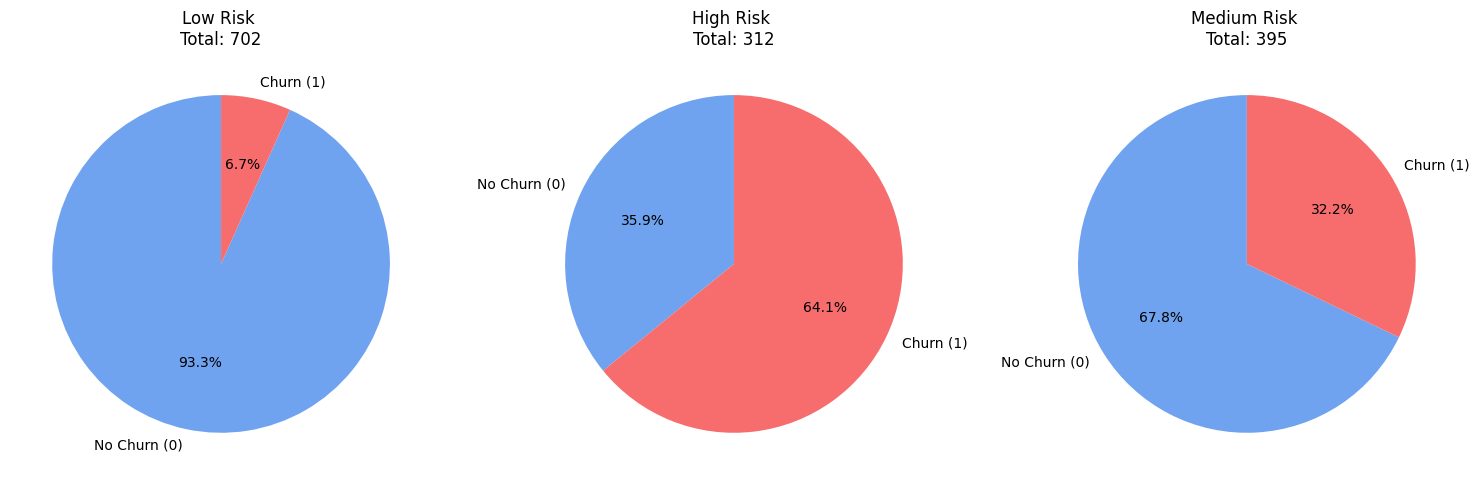

In [202]:
import matplotlib.pyplot as plt

risk_levels = lr_results['Churn Risk'].unique()

fig, axes = plt.subplots(1, len(risk_levels), figsize=(5 * len(risk_levels), 5))

if len(risk_levels) == 1:
    axes = [axes]

for i, level in enumerate(risk_levels):
    group = lr_results[lr_results['Churn Risk'] == level]
    churn_counts = group['Actual Churn'].value_counts().sort_index()
    churn_counts = churn_counts.reindex([0, 1], fill_value=0)

    labels = ['No Churn (0)', 'Churn (1)']
    colors = ['#6FA3EF', '#F76C6C']
    axes[i].pie(churn_counts, labels=labels, autopct='%1.1f%%', startangle=90, colors=colors)
    axes[i].set_title(f'{level} \nTotal: {len(group)}')

plt.tight_layout()
plt.show()


In [204]:

xgb_risk_levels = []

for prob in y_proba_xgb:
    if prob >= 0.7:
        xgb_risk_levels.append('High Risk')
    elif prob >= 0.4:
        xgb_risk_levels.append('Medium Risk')
    else:
        xgb_risk_levels.append('Low Risk')


In [205]:

xgb_results = X_test.copy()
xgb_results['Churn Probability'] = y_proba_xgb
xgb_results['Churn Risk'] = xgb_risk_levels
xgb_results['Actual Churn'] = y_test.values

xgb_results[['Churn Probability', 'Churn Risk', 'Actual Churn']].tail(20)


,Churn Probability,Churn Risk,Actual Churn
6728,0.001817,Low Risk,0
6460,0.744851,High Risk,0
4718,0.464579,Medium Risk,0
2118,0.009403,Low Risk,0
758,0.926731,High Risk,1
6587,0.001948,Low Risk,0
6576,0.604773,Medium Risk,0
4986,0.633212,Medium Risk,0
3148,0.270967,Low Risk,0
5612,0.001775,Low Risk,0


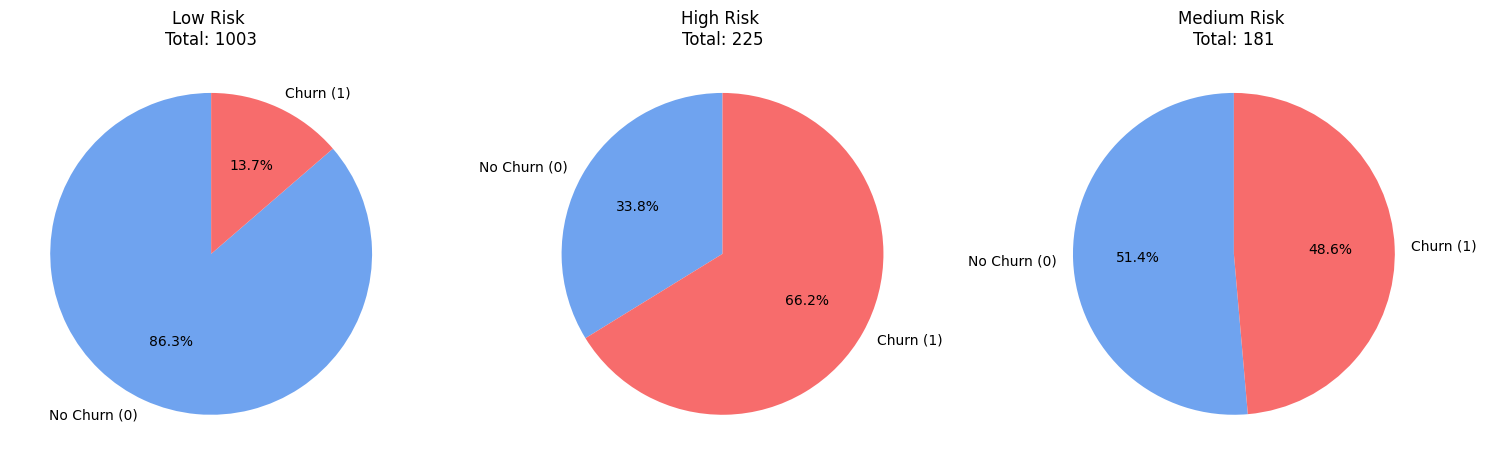

In [208]:
import matplotlib.pyplot as plt

risk_levels = xgb_results['Churn Risk'].unique()
fig, axes = plt.subplots(1, len(risk_levels), figsize=(5 * len(risk_levels), 5))

if len(risk_levels) == 1:
    axes = [axes]

for i, level in enumerate(risk_levels):  
    group = xgb_results[xgb_results['Churn Risk'] == level]
    churn_counts = group['Actual Churn'].value_counts().sort_index()
    churn_counts = churn_counts.reindex([0, 1], fill_value=0)

    labels = ['No Churn (0)', 'Churn (1)']
    colors = ['#6FA3EF', '#F76C6C']
    axes[i].pie(churn_counts, labels=labels, autopct='%1.1f%%', startangle=90, colors=colors)
    axes[i].set_title(f'{level} \nTotal: {len(group)}')

plt.tight_layout()
plt.show()


In [211]:
rf_risk_levels = []
for prob in y_proba_rf:
    if prob >= 0.7:
        rf_risk_levels.append('High Risk')
    elif prob >= 0.4:
        rf_risk_levels.append('Medium Risk')
    else:
        rf_risk_levels.append('Low Risk')


In [212]:
rf_results = X_test.copy()
rf_results['Churn Probability'] = y_proba_rf
rf_results['Churn Risk'] = rf_risk_levels
rf_results['Actual Churn'] = y_test.values

print(rf_results[['Churn Probability', 'Churn Risk', 'Actual Churn']].tail(20))


      Churn Probability   Churn Risk  Actual Churn
6728              0.010     Low Risk             0
6460              0.510  Medium Risk             0
4718              0.440  Medium Risk             0
2118              0.005     Low Risk             0
758               0.595  Medium Risk             1
6587              0.000     Low Risk             0
6576              0.505  Medium Risk             0
4986              0.690  Medium Risk             0
3148              0.000     Low Risk             0
5612              0.000     Low Risk             0
375               0.600  Medium Risk             1
5386              0.115     Low Risk             0
1985              0.005     Low Risk             0
5343              0.005     Low Risk             0
4598              0.010     Low Risk             0
5660              0.000     Low Risk             0
5150              0.000     Low Risk             0
4708              0.030     Low Risk             0
5381              0.015     Low

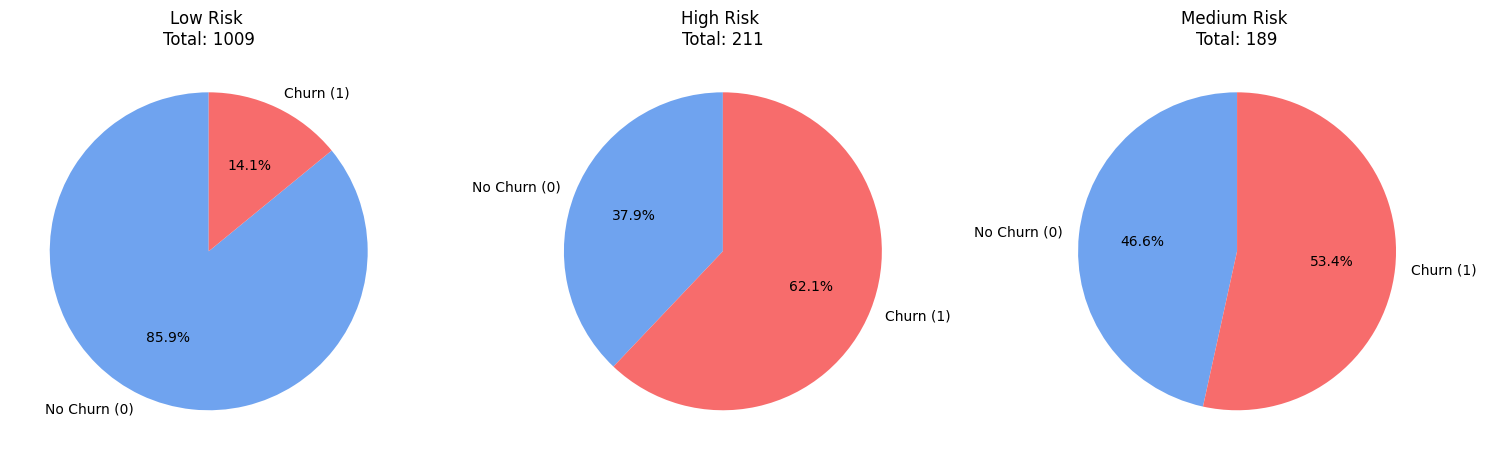

In [213]:
risk_levels = rf_results['Churn Risk'].unique()

fig, axes = plt.subplots(1, len(risk_levels), figsize=(5 * len(risk_levels), 5))

if len(risk_levels) == 1:
    axes = [axes]

for i, level in enumerate(risk_levels):
    group = rf_results[rf_results['Churn Risk'] == level]
    churn_counts = group['Actual Churn'].value_counts().sort_index()
    churn_counts = churn_counts.reindex([0, 1], fill_value=0)  # Ensure both 0 and 1 appear

    labels = ['No Churn (0)', 'Churn (1)']
    colors = ['#6FA3EF', '#F76C6C']
    axes[i].pie(churn_counts, labels=labels, autopct='%1.1f%%', startangle=90, colors=colors)
    axes[i].set_title(f'{level} \nTotal: {len(group)}')

plt.tight_layout()
plt.show()

 Threshold tuning: Try adjusting the classification threshold from default 0.5 to improve recall or precision.
 Export model: Save best model with joblib or pickle for deployment.